## Неделя 3. Среда
### Временные ряды

В этом задании тебе предстоит проанализировать продажи разных категорий товаров. Сначала это стоит сделать для одной категории, потом можно попробовать для других. 

# 1. Загрузи [датасет](https://community.tableau.com/s/question/0D54T00000CWeX8SAL/sample-superstore-sales-excelxls) и распечатай первые 10 строк. 

In [112]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

from prophet.diagnostics import cross_validation, performance_metrics
from itertools import product

from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

In [2]:
plt.style.use('seaborn-v0_8')

In [3]:
df = pd.read_excel('Sample - Superstore.xls')
df = df[df['Category'] == 'Furniture']

Сделай выборку по категории товара (используй популярную категорию: например, `Furniture`) и запиши в переменную `data`. Распечатай первые 10 строк. 

In [4]:
data = df[df["Category"] == "Furniture"]
data.head(10)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
5,6,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600,7,0.00,14.1694
10,11,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-TA-10001539,Furniture,Tables,Chromcraft Rectangular Conference Tables,1706.1840,9,0.20,85.3092
23,24,US-2017-156909,2017-07-16,2017-07-18,Second Class,SF-20065,Sandra Flanagan,Consumer,United States,Philadelphia,...,19140,East,FUR-CH-10002774,Furniture,Chairs,"Global Deluxe Stacking Chair, Gray",71.3720,2,0.30,-1.0196
24,25,CA-2015-106320,2015-09-25,2015-09-30,Standard Class,EB-13870,Emily Burns,Consumer,United States,Orem,...,84057,West,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,1044.6300,3,0.00,240.2649
27,28,US-2015-150630,2015-09-17,2015-09-21,Standard Class,TB-21520,Tracy Blumstein,Consumer,United States,Philadelphia,...,19140,East,FUR-BO-10004834,Furniture,Bookcases,"Riverside Palais Royal Lawyers Bookcase, Royal...",3083.4300,7,0.50,-1665.0522
29,30,US-2015-150630,2015-09-17,2015-09-21,Standard Class,TB-21520,Tracy Blumstein,Consumer,United States,Philadelphia,...,19140,East,FUR-FU-10004848,Furniture,Furnishings,"Howard Miller 13-3/4"" Diameter Brushed Chrome ...",124.2000,3,0.20,15.5250
36,37,CA-2016-117590,2016-12-08,2016-12-10,First Class,GH-14485,Gene Hale,Corporate,United States,Richardson,...,75080,Central,FUR-FU-10003664,Furniture,Furnishings,"Electrix Architect's Clamp-On Swing Arm Lamp, ...",190.9200,5,0.60,-147.9630


In [5]:
data = data.drop(columns=["Row ID"])

# 2. Визуализируй данные:
    * по исходному целевому столбцу (`Sales`)
    * усреднить просуммировать по разным периодам (неделя, месяц, квартал, полугодие)

In [21]:
# будет получать зависимость между датой оформления заказа и sales

In [6]:
# перевожу в дату
data["Order Date"] = pd.to_datetime(data["Order Date"])
data["Order Date"].dtypes

dtype('<M8[us]')

In [7]:
# нужно сделать Order Date индексом датафрейма, чтобы группировать продажи по временным периодам
data = data.set_index('Order Date')

In [8]:
data.index

DatetimeIndex(['2016-11-08', '2016-11-08', '2015-10-11', '2014-06-09',
               '2014-06-09', '2017-07-16', '2015-09-25', '2015-09-17',
               '2015-09-17', '2016-12-08',
               ...
               '2015-11-13', '2016-06-03', '2016-12-12', '2017-06-01',
               '2015-12-14', '2015-03-19', '2016-12-05', '2015-09-06',
               '2014-01-21', '2017-02-26'],
              dtype='datetime64[us]', name='Order Date', length=2121, freq=None)

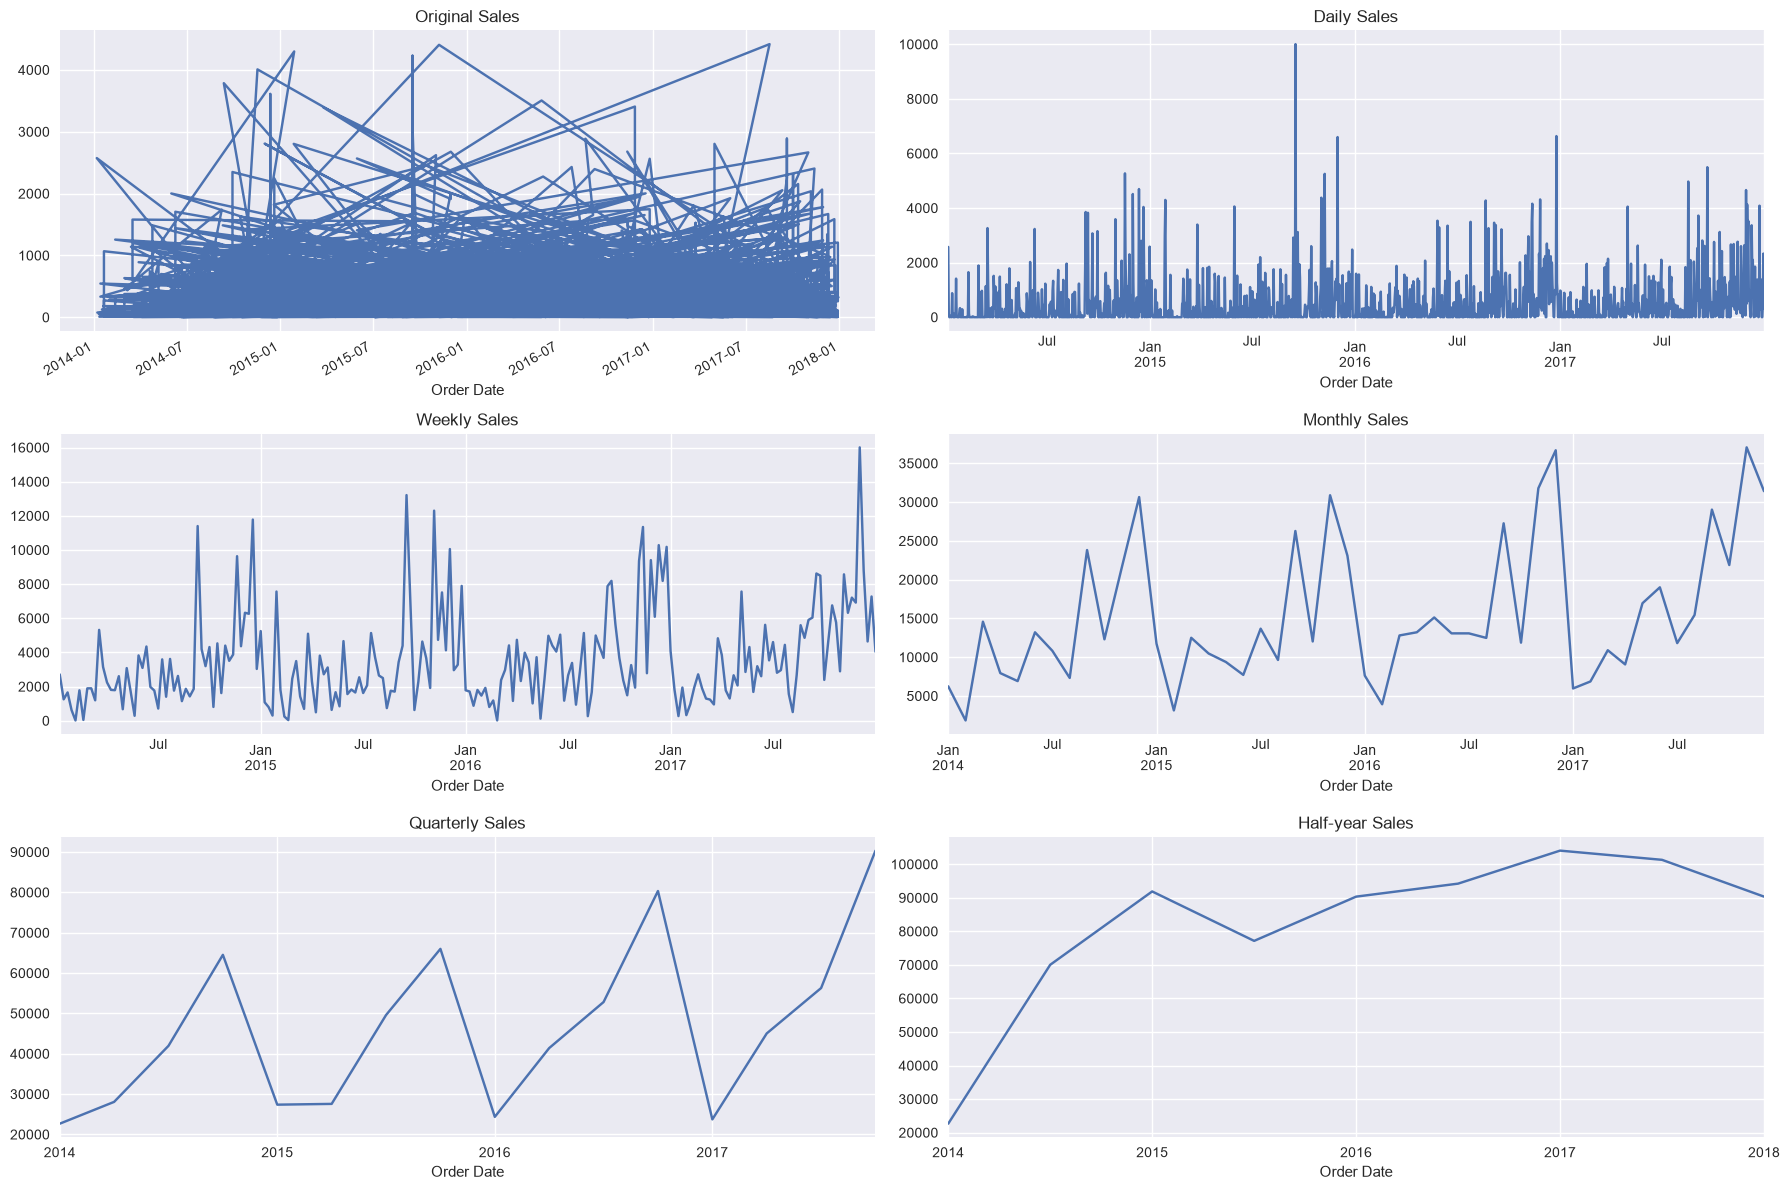

In [23]:
fig, ax = plt.subplots(3, 2, figsize=(18, 12))

data["Sales"].plot(ax=ax[0, 0], title="Original Sales")
data["Sales"].resample("D").sum().plot(ax=ax[0, 1], title="Daily Sales")
data["Sales"].resample("W").sum().plot(ax=ax[1, 0], title="Weekly Sales")
data["Sales"].resample("ME").sum().plot(ax=ax[1, 1], title="Monthly Sales")
data["Sales"].resample("QE").sum().plot(ax=ax[2, 0], title="Quarterly Sales")
data["Sales"].resample("2QE").sum().plot(ax=ax[2, 1], title="Half-year Sales")

plt.tight_layout() # автоматически регулирует расположение графиков
plt.show()

In [15]:
# data["Sales"].resample("D").sum().plot(
#     kind="bar",
#     figsize=(15, 5))
# plt.show() # это график бар

усреднить просуммировать по разным периодам (неделя, месяц, квартал, полугодие)

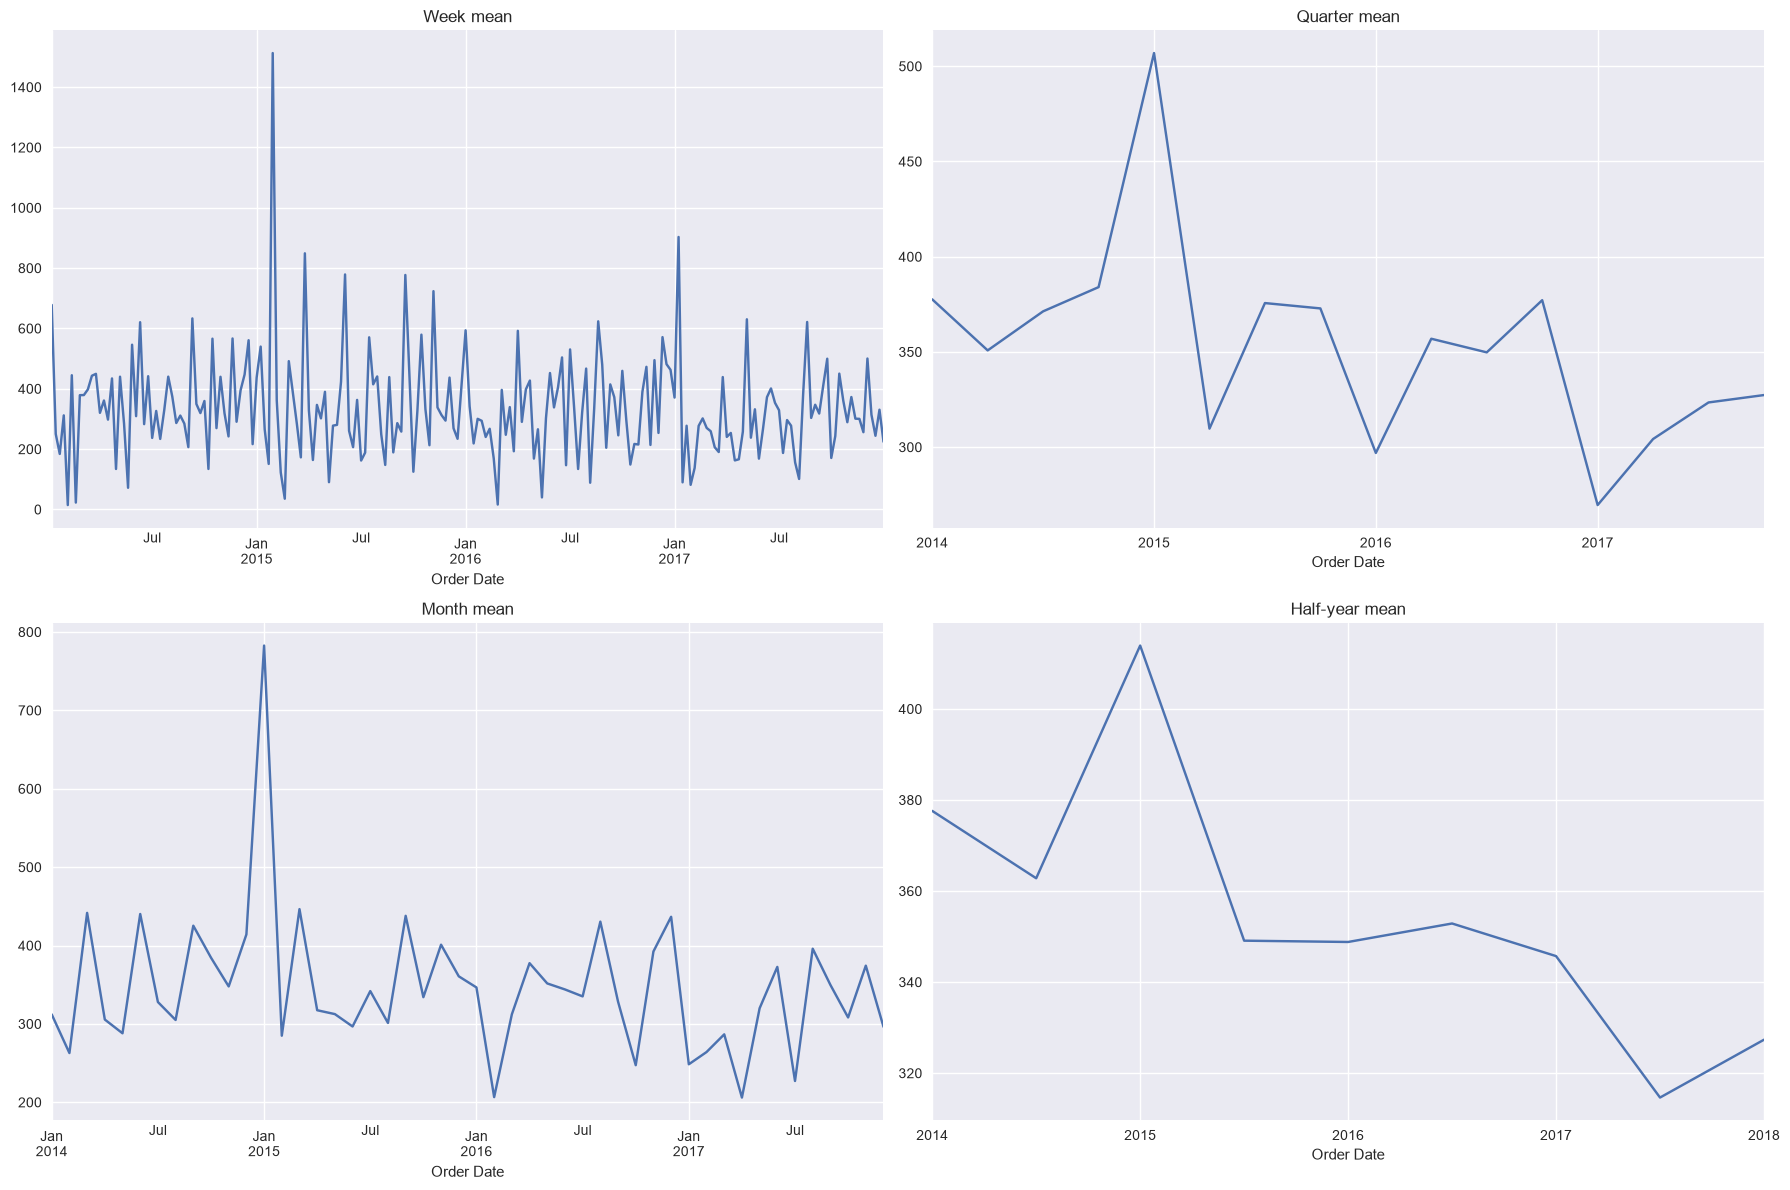

In [26]:
fix, ax = plt.subplots(2, 2, figsize=(18, 12))

data["Sales"].resample("W").mean().plot(ax=ax[0, 0], title="Week mean")
data["Sales"].resample("ME").mean().plot(ax=ax[1, 0], title="Month mean")
data["Sales"].resample("QE").mean().plot(ax=ax[0, 1], title="Quarter mean")
data["Sales"].resample("2QE").mean().plot(ax=ax[1, 1], title="Half-year mean")

plt.tight_layout()
plt.show()

# 2.1 В качестве анализа необходимо взять временной ряд по __неделям__, и анализировать __сумму__. 

In [27]:
data["Sales"].resample("W").sum()

Order Date
2014-01-12     2712.4280
2014-01-19     1250.4730
2014-01-26     1655.9580
2014-02-02      623.6660
2014-02-09       14.5600
                 ...    
2017-12-03    16008.1720
2017-12-10     8794.4040
2017-12-17     4639.8190
2017-12-24     7274.0430
2017-12-31     4037.5648
Freq: W-SUN, Name: Sales, Length: 208, dtype: float64

In [31]:
data_week = data["Sales"].resample("W").sum()

In [29]:
data_week.head()

Order Date
2014-01-12    2712.428
2014-01-19    1250.473
2014-01-26    1655.958
2014-02-02     623.666
2014-02-09      14.560
Freq: W-SUN, Name: Sales, dtype: float64

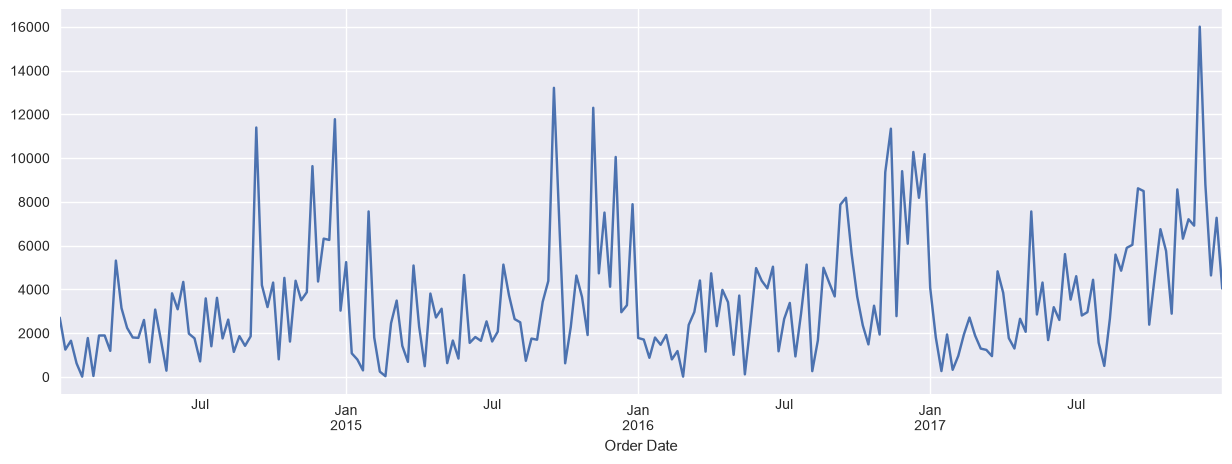

In [33]:
data_week.plot(figsize=(15, 5))
plt.show()

# 3. Построй визуализации:
* скользящего среднего


In [40]:
# рассчитаем скользящее среднее с окном в 4 недели
data_week.rolling(window=4).mean()

Order Date
2014-01-12           NaN
2014-01-19           NaN
2014-01-26           NaN
2014-02-02    1560.63125
2014-02-09     886.16425
                 ...    
2017-12-03    9112.31725
2017-12-10    9731.27675
2017-12-17    9089.32275
2017-12-24    9179.10950
2017-12-31    6186.45770
Freq: W-SUN, Name: Sales, Length: 208, dtype: float64

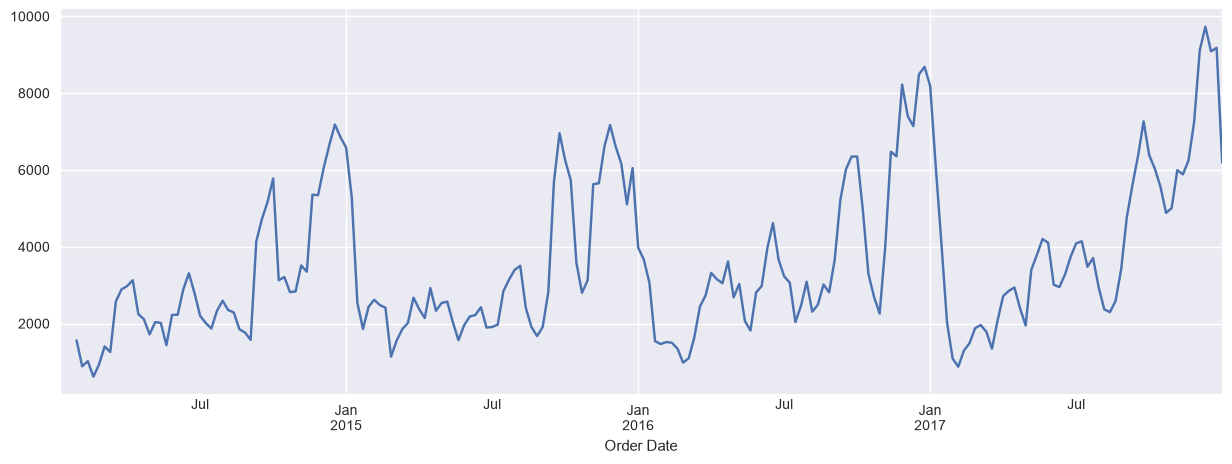

In [39]:
data_week_roll = data_week.rolling(window=4).mean()
data_week_roll.plot(figsize=(15, 5))
plt.show()

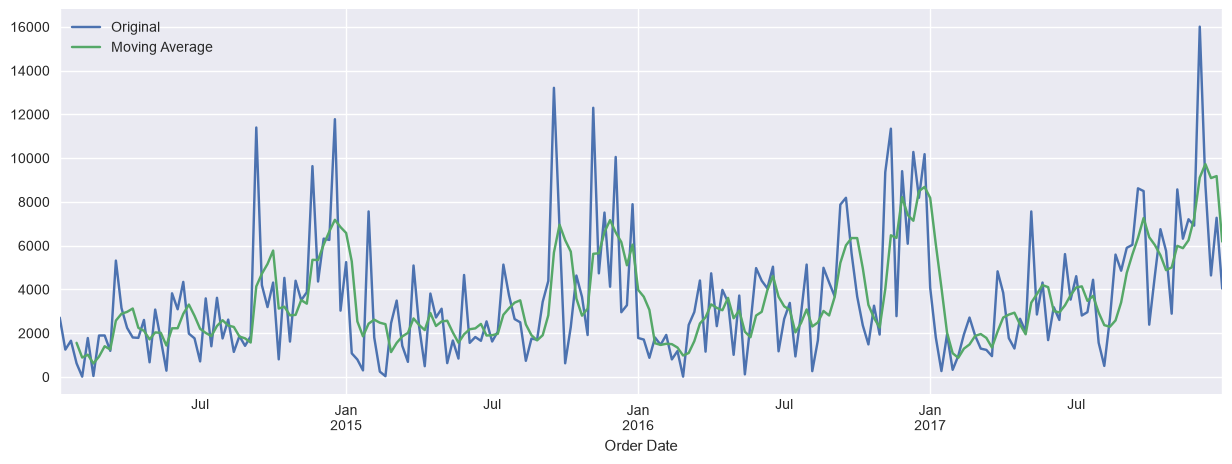

In [41]:
# теперь сравним исходный временной ряд и скользящее среднее на одном графике. 
# Так будет нагляднее видно, как сглаживаются колебания

fig, ax = plt.subplots(figsize=(15, 5))

data_week.plot(ax=ax, label='Original')
data_week_roll.plot(ax=ax, label='Moving Average')

ax.legend()
plt.show()


* взвешенного скользящего среднего


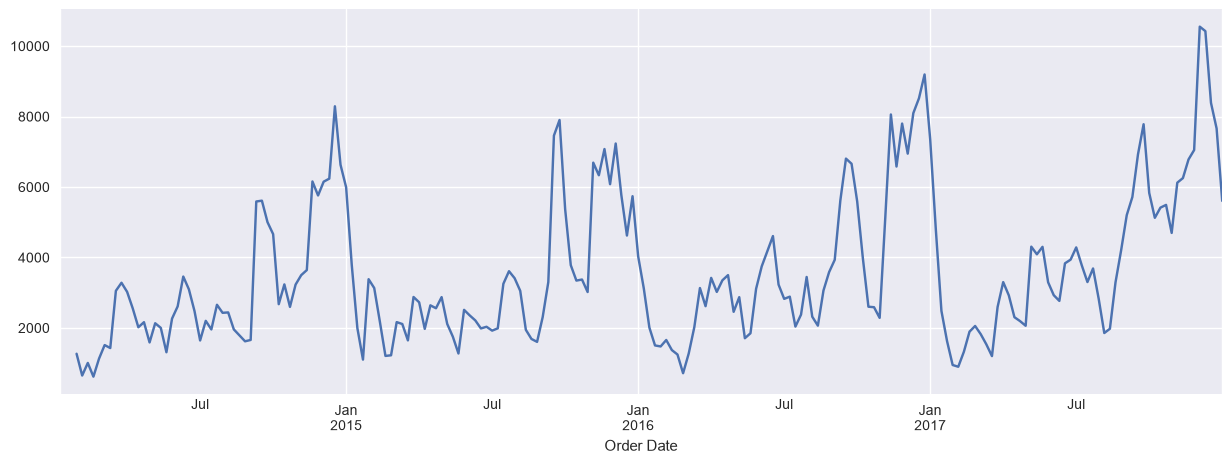

In [43]:
# окно = 4 недели, и веса [1, 2, 3, 4]
# последняя неделя получает больший вес, потому что она ближе всего в текущему моменту

weights = np.array([1, 2, 3, 4]) # веса
data_week_wma = data_week.rolling(window=4).apply(
    lambda x: np.dot(x, weights) / weights.sum()) # рассчитываем взвешенное среднее
# np.dot gеремножает каждую продажу на соответствующий вес и складывает результаты

data_week_wma.plot(figsize=(15, 5))
plt.show()

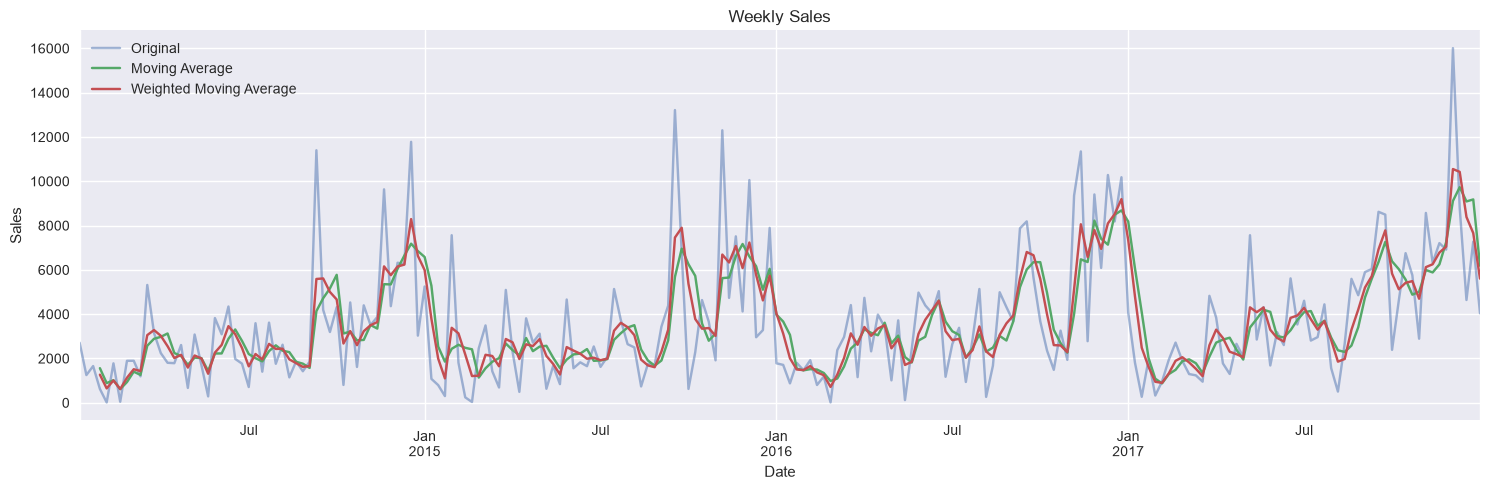

In [46]:
fig, ax = plt.subplots(figsize=(15, 5))

data_week.plot(ax=ax, label='Original', alpha=0.5)
data_week_roll.plot(ax=ax, label='Moving Average')
data_week_wma.plot(ax=ax, label='Weighted Moving Average')

ax.set_title('Weekly Sales')
ax.set_xlabel('Date')
ax.set_ylabel('Sales')
ax.legend()

plt.tight_layout()
plt.show()
# alpha=0.5 - прозраность линии на графике

Какие выводы можно сделать по скользящим линиям? Что они показывают?

Скользящее среднее позволяет сгладить краткосрочные колебания недельных продаж и выявить общую тенденцию временного ряда.  
Взвешенное скользящее среднее сильнее учитывает последние наблюдения, поэтому быстрее реагирует на изменения.  
Оба метода помогают лучше оценить динамику продаж.

# 4. Декомпозируй данные на тренд, сезонность и остатки. 

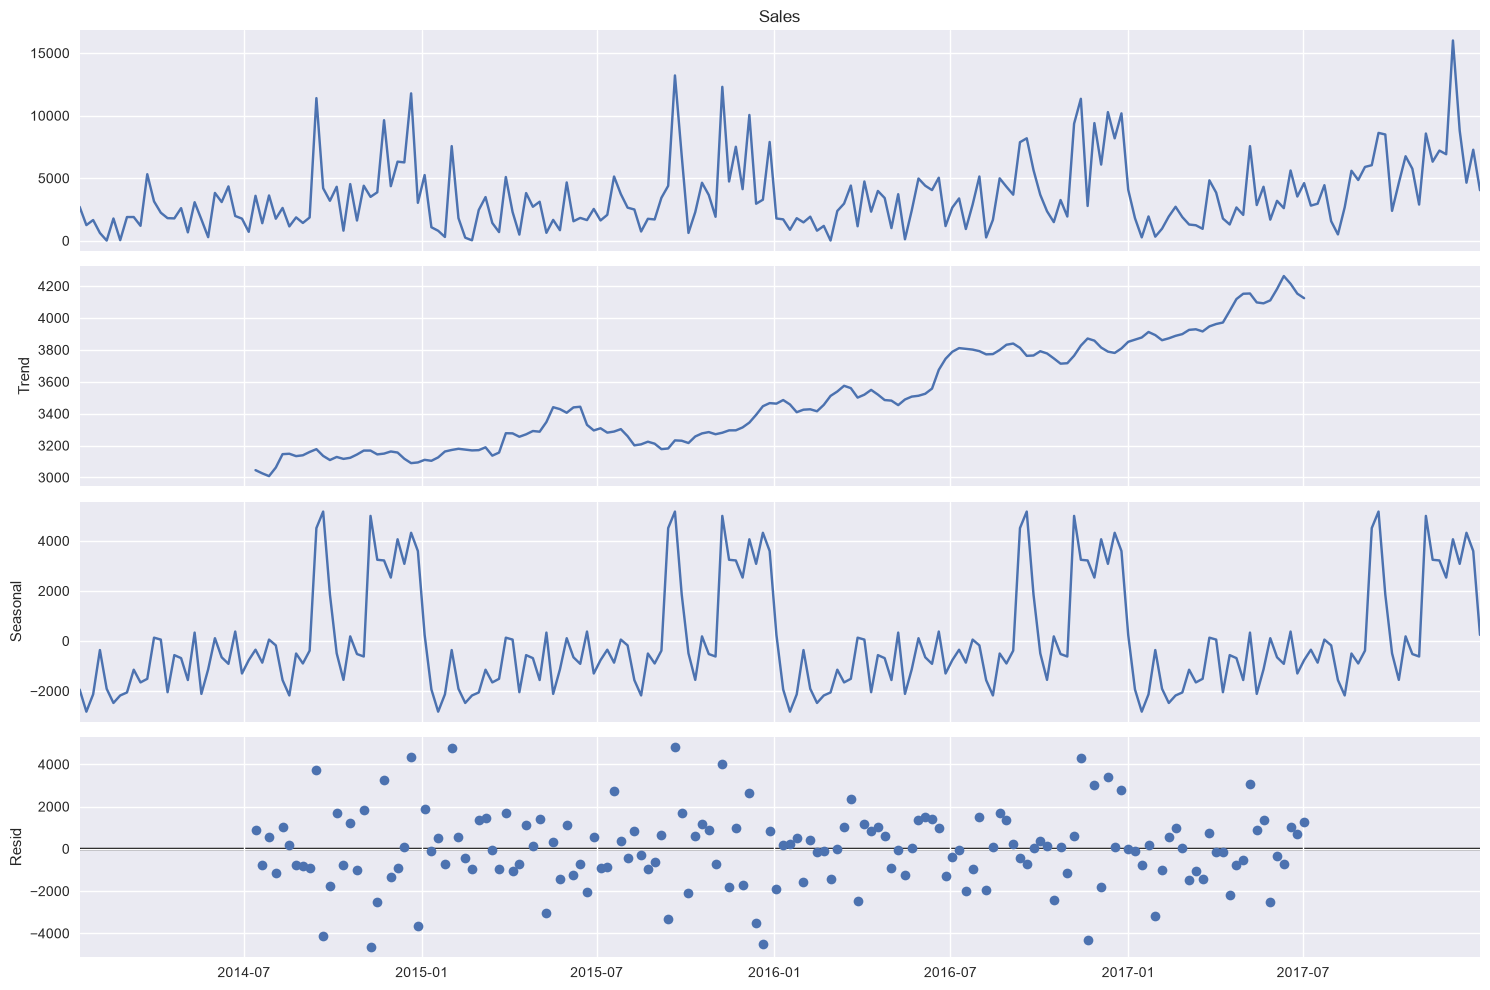

In [63]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Декомпозиция — это разложение временного ряда на три составляющие:
# 1. Observed — исходный временной ряд, наши недельные продажи.
# 2. Trend (тренд) — общее направление изменения продаж: растут они или снижаются.
# 3. Seasonality (сезонность) — повторяющиеся закономерности через определённые промежутки времени.
# 4. Residual (остатки) — случайные колебания, которые не объясняются трендом и сезонностью.

decomposition = seasonal_decompose(data_week, model="additive", period=52)
# data_week — наш временной ряд;
# model='additive' — аддитивная модель декомпозиции;
# period=52 — предполагаем, что сезонность повторяется каждые 52 недели (примерно год).

fig = decomposition.plot()
fig.set_size_inches(15, 10)
plt.tight_layout()
plt.show()

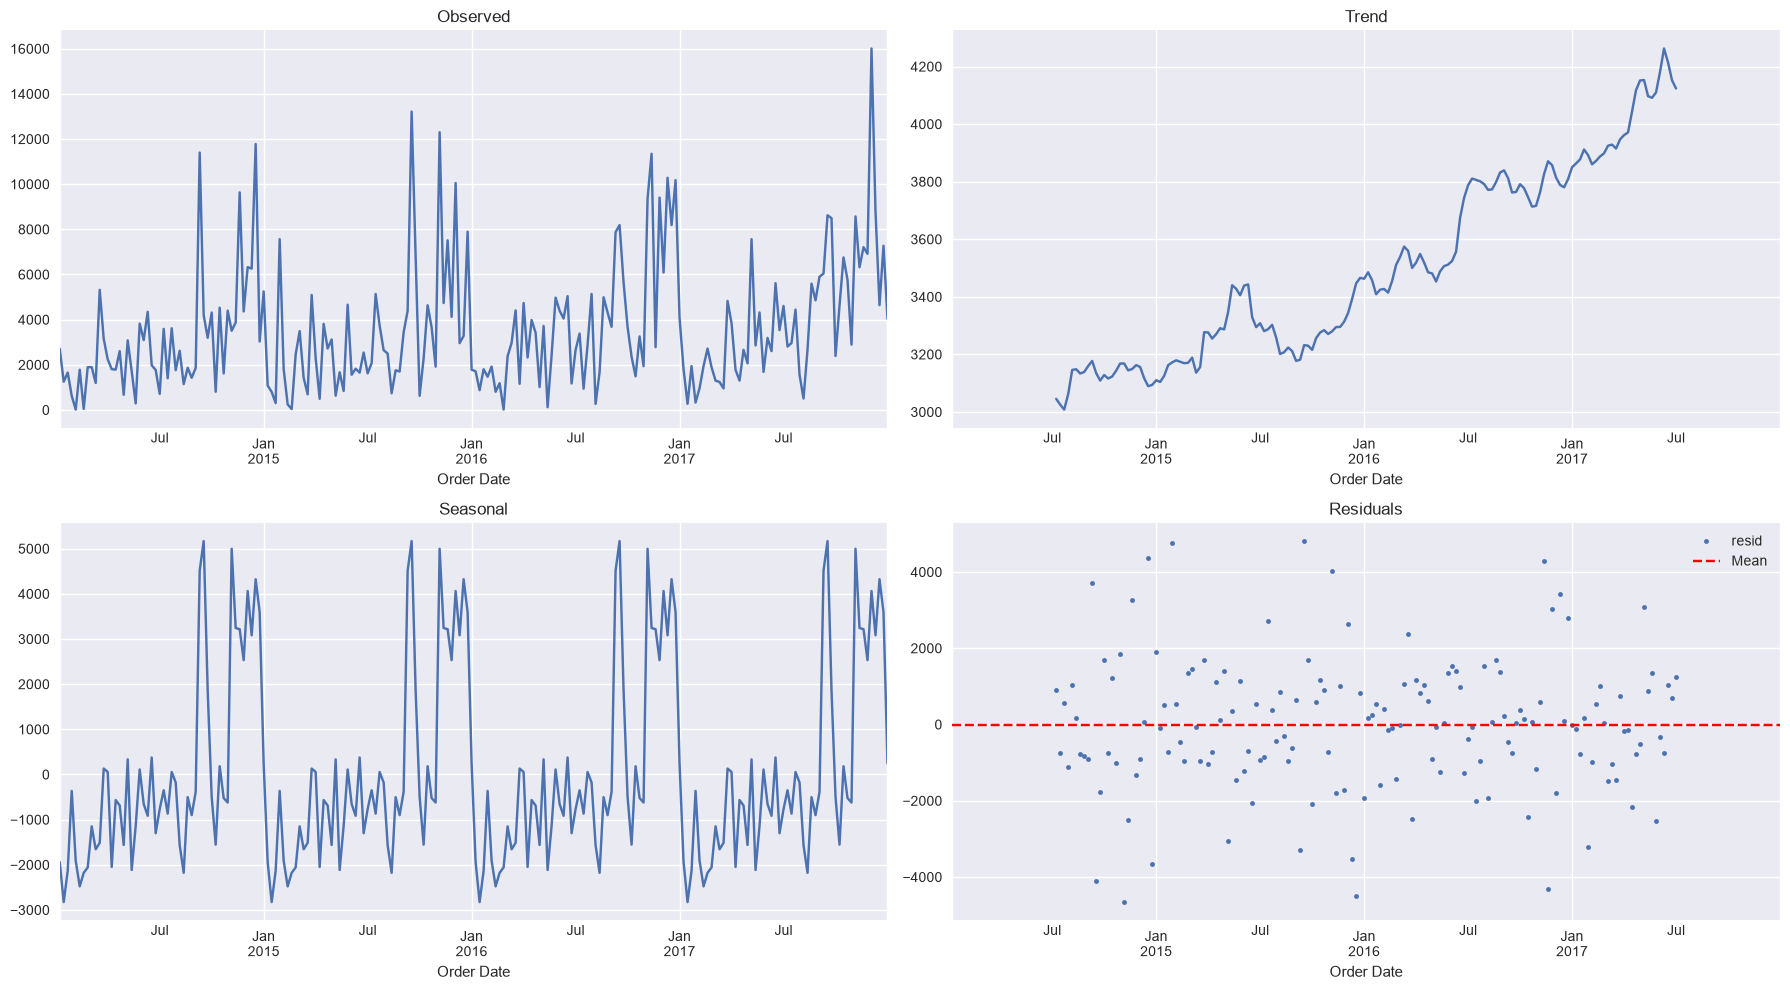

In [66]:
fig, ax = plt.subplots(2, 2, figsize=(18, 10))

decomposition.observed.plot(ax=ax[0, 0], title="Observed")
decomposition.trend.plot(ax=ax[0, 1], title="Trend")
decomposition.seasonal.plot(ax=ax[1, 0], title="Seasonal")
decomposition.resid.plot(ax=ax[1, 1], title="Residuals", style='.')

ax[1, 1].axhline(
    decomposition.resid.mean(),
    color='red',
    linestyle='--',
    label='Mean'
)

ax[1, 1].legend()

plt.tight_layout()
plt.show()

In [55]:
print('Средние продажи:', data_week.mean())
print('Средняя абсолютная величина остатков:', decomposition.resid.abs().mean())
print('Максимальная абсолютная величина остатков:', decomposition.resid.abs().max())

Средние продажи: 3567.3067081730774
Средняя абсолютная величина остатков: 1322.1870219304733
Максимальная абсолютная величина остатков: 4811.692348317308


# ❓
Прокомментируй графики: какой вывод можно сделать? Есть ли в данных сезонность? Какой тренд преобладает? Какого масштаба ошибки по сравнению со значениями основного временного ряда?

Декомпозиция позволяет разделить временной ряд на тренд, сезонность и остатки. Средний уровень недельных продаж составляет около 3567, а средняя абсолютная величина остатков — около 1322, что соответствует примерно 37% от среднего значения продаж. Это говорит о том, что необъяснённые колебания достаточно существенны. Максимальная абсолютная величина остатков составляет около 4812.

# 5. Построй графики автокорреляционной функции и частичной автокорреляционной функции. 

In [68]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

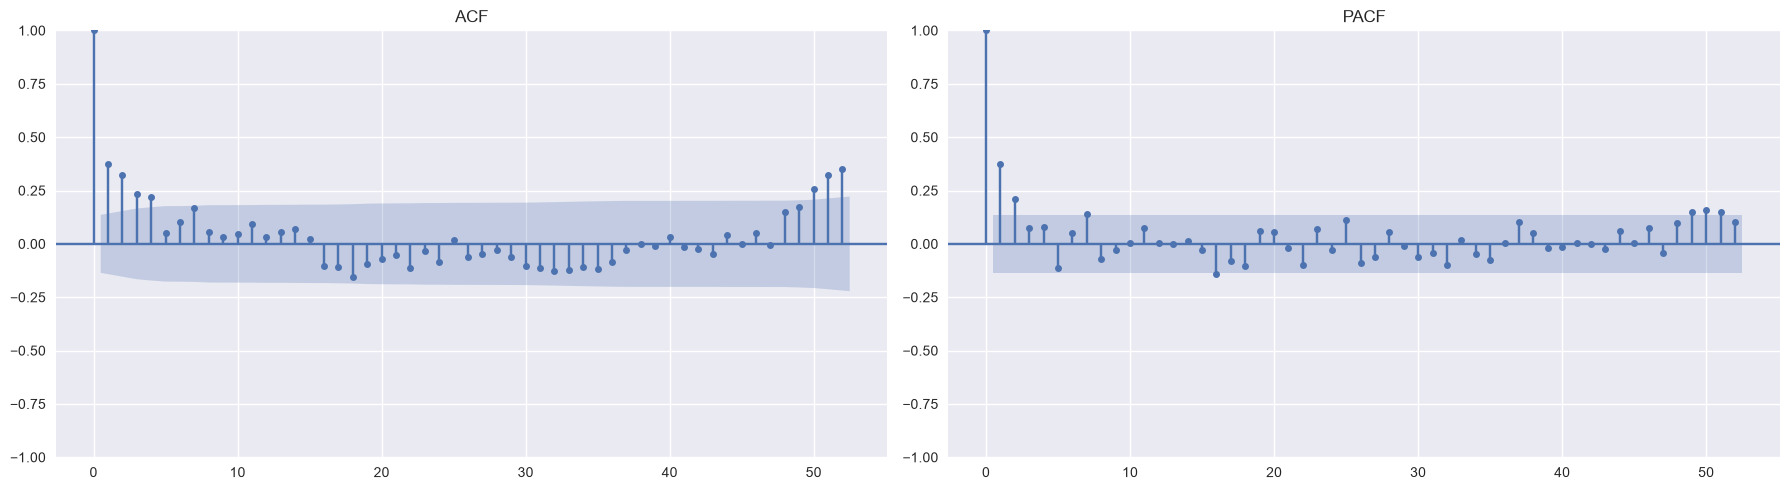

In [67]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5))

plot_acf(data_week, ax=ax[0], lags=52)
plot_pacf(data_week, ax=ax[1], lags=52)

ax[0].set_title('ACF')
ax[1].set_title('PACF')

plt.tight_layout()
plt.show()

1. ACF: в первых лагах наблюдается положительная автокорреляция. Это означает, что продажи текущей недели связаны с продажами предыдущих недель.
2. По мере увеличения лага автокорреляция снижается, становится отрицательной, а затем снова растёт.
3. В конце графика ACF (лаги 50–52) появляются заметные положительные пики. Это может указывать на годовую сезонность — повторение динамики продаж примерно через 52 недели.
4. PACF: наиболее выраженная связь наблюдается с первым и вторым лагами. Большинство остальных значений находятся внутри доверительного интервала, то есть их отдельное влияние не столь выражено.

# ❓
Какие выводы можно сделать на основе этих графиков?

По графикам ACF и PACF можно сделать вывод, что недельные продажи имеют автокорреляцию: текущие значения связаны с предыдущими неделями. Также наблюдаются признаки годовой сезонности, поскольку на графике ACF заметен рост автокорреляции в районе 52-го лага. Наиболее выраженная прямая связь наблюдается с первыми двумя лагами.

# 6. Постройте и визуализируйте модель класса ARIMA

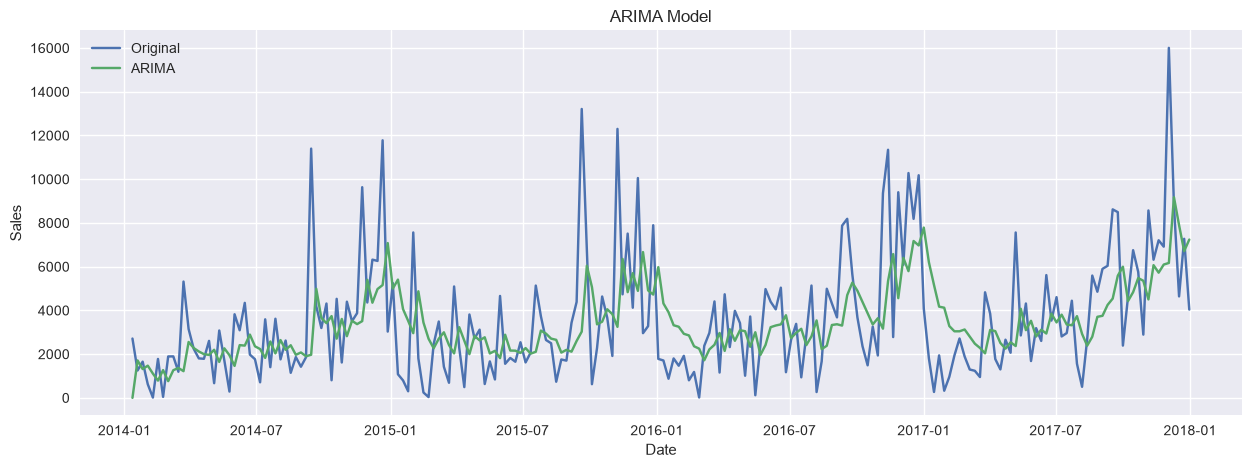

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
# AR (AutoRegressive) — авторегрессия. Использует предыдущие значения ряда для прогноза.
# I (Integrated) — интегрированная. Убирает тренд с помощью разностей между соседними значениями.
# MA (Moving Average) — скользящее среднее. Учитывает предыдущие ошибки прогнозирования.

model_arima = ARIMA(data_week, order=(1, 1, 1))
model_arima_fit = model_arima.fit()

plt.figure(figsize=(15, 5))

plt.plot(data_week, label='Original')
plt.plot(model_arima_fit.fittedvalues, label='ARIMA')

plt.title('ARIMA Model')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()

plt.show()

# 7. Постройте и визуализируйте модель prophet. Попробуйте подобрать оптимальные параметры

In [80]:
from prophet import Prophet
# Prophet требует, чтобы в таблице было два столбца:
# - ds — дата;
# - y — значение временного ряда.

data_prophet = data_week.rename_axis('ds').reset_index(name='y')
data_prophet.head()

,ds,y
0,2014-01-12,2712.428
1,2014-01-19,1250.473
2,2014-01-26,1655.958
3,2014-02-02,623.666
4,2014-02-09,14.560


In [81]:
model = Prophet()
model.fit(data_prophet)

14:24:47 - cmdstanpy - INFO - Chain [1] start processing
14:24:48 - cmdstanpy - INFO - Chain [1] done processing


In [82]:
# получаем прогноз на 52 недели
future = model.make_future_dataframe(periods=52, freq="W")

forecast = model.predict(future)

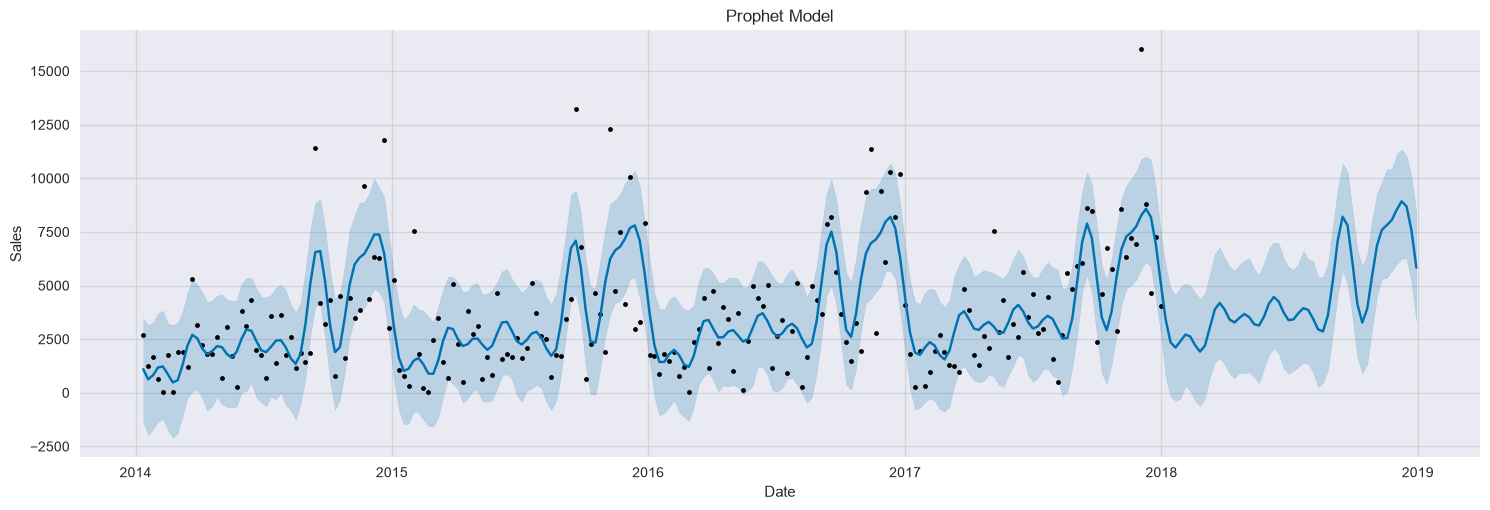

In [83]:
model.plot(forecast, figsize=(15, 5))

plt.title('Prophet Model')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.show()

In [ ]:
# Точки — реальные недельные продажи.
# Сплошная линия — прогноз модели Prophet (yhat).
# Заштрихованная область вокруг линии — доверительный интервал прогноза (yhat_lower и yhat_upper).
# yhat — основное прогнозируемое значение.
# yhat_lower — нижняя граница прогноза.
# yhat_upper — верхняя граница прогноза.
# yhat = 4000
# yhat_lower = 3000
# yhat_upper = 5000

In [ ]:
# Подберём параметры Prophet с помощью перекрёстной проверки для временных рядов (cross_validation). 
# Будем сравнивать модели по MAE и RMSE: чем меньше эти значения, тем точнее прогноз.
# Попробуем подобрать три параметра:
# - changepoint_prior_scale — насколько гибко модель реагирует на изменения тренда;
# - seasonality_prior_scale — насколько выраженной может быть сезонность;
# - seasonality_mode — тип сезонности: аддитивная или мультипликативная.

In [84]:
from prophet.diagnostics import cross_validation, performance_metrics
from itertools import product

In [88]:
# задаём варианты параментров
changepoint_prior_scale = [0.01, 0.05, 0.1]
seasonality_prior_scale = [0.1, 1]
seasonality_mode = ['additive', 'multiplicative']

In [89]:
# проверяем комбинации

results = []

for cps, sps, mode in product(
    changepoint_prior_scale,
    seasonality_prior_scale,
    seasonality_mode
):
    model = Prophet(
        changepoint_prior_scale=cps,
        seasonality_prior_scale=sps,
        seasonality_mode=mode
    )

    model.fit(data_prophet)

    df_cv = cross_validation(
        model,
        initial='730 days',
        period='180 days',
        horizon='365 days'
    )

    df_metrics = performance_metrics(df_cv)

    results.append({
        'changepoint_prior_scale': cps,
        'seasonality_prior_scale': sps,
        'seasonality_mode': mode,
        'MAE': df_metrics['mae'].mean(),
        'RMSE': df_metrics['rmse'].mean()
    })

14:45:13 - cmdstanpy - INFO - Chain [1] start processing
14:45:13 - cmdstanpy - INFO - Chain [1] done processing
  0%|          | 0/2 [00:00<?, ?it/s]14:45:13 - cmdstanpy - INFO - Chain [1] start processing
14:45:13 - cmdstanpy - INFO - Chain [1] done processing
 50%|█████     | 1/2 [00:00<00:00,  5.25it/s]14:45:13 - cmdstanpy - INFO - Chain [1] start processing
14:45:13 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 2/2 [00:00<00:00,  5.50it/s]
14:45:14 - cmdstanpy - INFO - Chain [1] start processing
14:45:14 - cmdstanpy - INFO - Chain [1] done processing
  0%|          | 0/2 [00:00<?, ?it/s]14:45:14 - cmdstanpy - INFO - Chain [1] start processing
14:45:14 - cmdstanpy - INFO - Chain [1] done processing
 50%|█████     | 1/2 [00:00<00:00,  5.83it/s]14:45:14 - cmdstanpy - INFO - Chain [1] start processing
14:45:14 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 2/2 [00:00<00:00,  5.86it/s]
14:45:14 - cmdstanpy - INFO - Chain [1] start processing
14:45:14 

In [90]:
# сравниваем результаты
results = pd.DataFrame(results)
results = results.sort_values('MAE')
results

,changepoint_prior_scale,seasonality_prior_scale,seasonality_mode,MAE,RMSE
6,0.05,1.0,additive,1668.812664,2095.929160
4,0.05,0.1,additive,1670.925186,2103.429730
8,0.10,0.1,additive,1677.381110,2095.575719
10,0.10,1.0,additive,1680.439565,2094.879171
0,0.01,0.1,additive,1691.246932,2142.364400
2,0.01,1.0,additive,1723.449876,2161.657899
11,0.10,1.0,multiplicative,1739.562561,2129.403677
7,0.05,1.0,multiplicative,1773.754665,2156.732713
5,0.05,0.1,multiplicative,1804.647255,2205.064603
9,0.10,0.1,multiplicative,1818.982683,2223.622790


In [91]:
best_params = results.iloc[0]
best_params

changepoint_prior_scale           0.05
seasonality_prior_scale            1.0
seasonality_mode              additive
MAE                        1668.812664
RMSE                        2095.92916
Name: 6, dtype: object

In [92]:
best_model = Prophet(
    changepoint_prior_scale=best_params['changepoint_prior_scale'],
    seasonality_prior_scale=best_params['seasonality_prior_scale'],
    seasonality_mode=best_params['seasonality_mode']
)

best_model.fit(data_prophet)

14:46:35 - cmdstanpy - INFO - Chain [1] start processing
14:46:35 - cmdstanpy - INFO - Chain [1] done processing


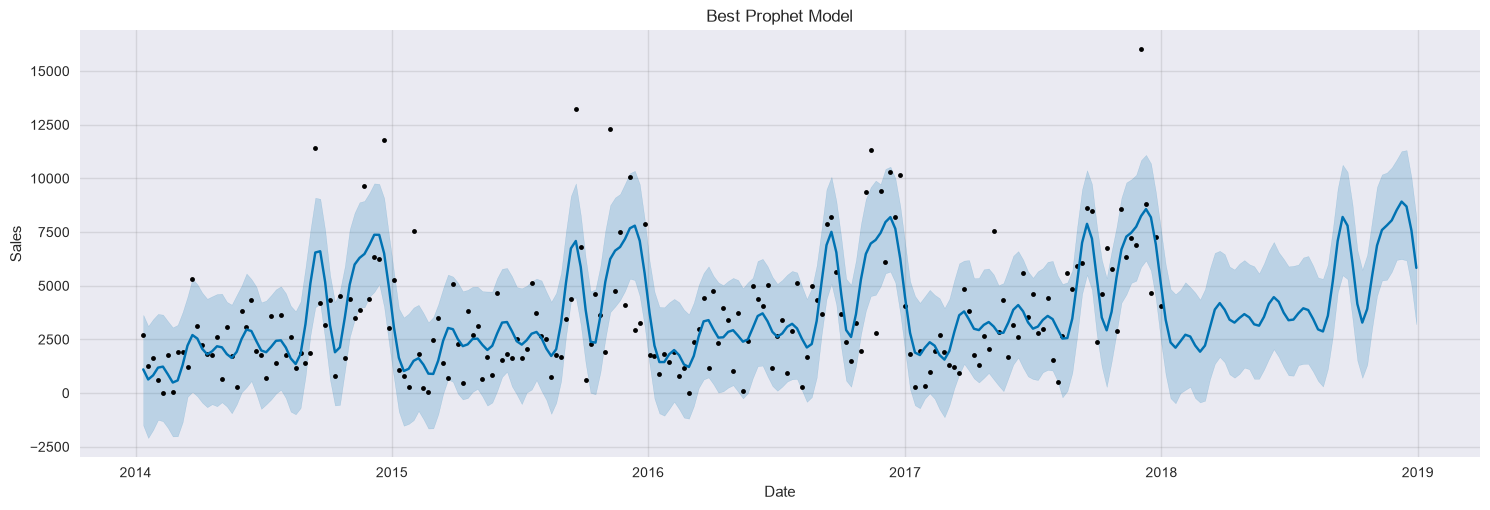

In [93]:
future = best_model.make_future_dataframe(periods=52, freq='W')

forecast = best_model.predict(future)

best_model.plot(forecast, figsize=(15, 5))

plt.title('Best Prophet Model')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.show()

In [96]:
# сравниваем Prophet с ARIMA
train = data_week.iloc[:-52]
test = data_week.iloc[-52:]



model_arima = ARIMA(train, order=(1, 1, 1))
model_arima_fit = model_arima.fit()

forecast_arima = model_arima_fit.forecast(steps=52)



train_prophet = train.rename_axis('ds').reset_index(name='y')

model_prophet = Prophet(
    changepoint_prior_scale=0.05,
    seasonality_prior_scale=1.0,
    seasonality_mode='additive'
)

model_prophet.fit(train_prophet)

future = model_prophet.make_future_dataframe(periods=52, freq='W')
forecast_prophet = model_prophet.predict(future)

forecast_prophet = forecast_prophet.set_index('ds')['yhat'].tail(52)

14:49:45 - cmdstanpy - INFO - Chain [1] start processing
14:49:45 - cmdstanpy - INFO - Chain [1] done processing


In [97]:
results = pd.DataFrame({
    'Model': ['ARIMA', 'Prophet'],
    'MAE': [
        mean_absolute_error(test, forecast_arima),
        mean_absolute_error(test, forecast_prophet)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(test, forecast_arima)),
        np.sqrt(mean_squared_error(test, forecast_prophet))
    ]
})

results

,Model,MAE,RMSE
0,ARIMA,3403.924555,3970.406681
1,Prophet,1704.673342,2247.969437


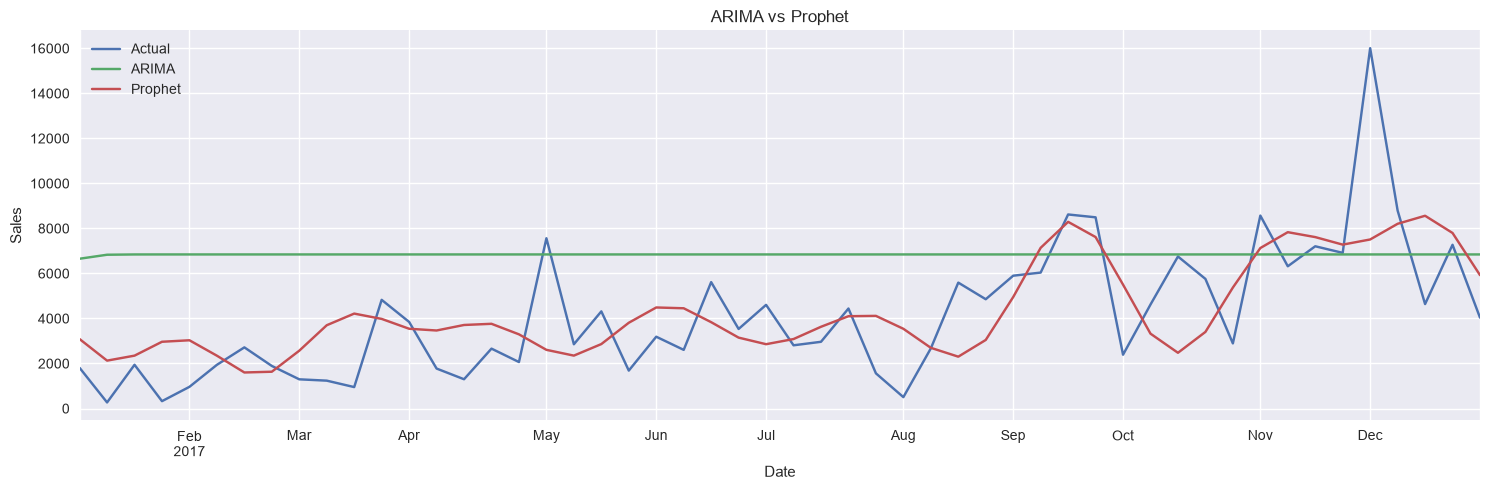

In [98]:
fig, ax = plt.subplots(figsize=(15, 5))

test.plot(ax=ax, label='Actual')
forecast_arima.plot(ax=ax, label='ARIMA')
forecast_prophet.plot(ax=ax, label='Prophet')

ax.set_title('ARIMA vs Prophet')
ax.set_xlabel('Date')
ax.set_ylabel('Sales')
ax.legend()

plt.tight_layout()
plt.show()

# 8. Примени регрессионные модели (случайный лес или градиентный бустинг) для прогнозирования целевой величины.
   * Пример есть в демо

In [101]:
# создаём признаки
# lag_1 — продажи предыдущей недели;
# lag_2 — продажи двух недель назад;
# lag_3 — продажи трёх недель назад;
# lag_4 — продажи четырёх недель назад;
# lag_52 — продажи за аналогичную неделю прошлого года.

data_ml = data_week.to_frame()

data_ml['lag_1'] = data_ml['Sales'].shift(1)
data_ml['lag_2'] = data_ml['Sales'].shift(2)
data_ml['lag_3'] = data_ml['Sales'].shift(3)
data_ml['lag_4'] = data_ml['Sales'].shift(4)
data_ml['lag_52'] = data_ml['Sales'].shift(52)

data_ml = data_ml.dropna()

data_ml.head()

,Sales,lag_1,lag_2,lag_3,lag_4,lag_52
Order Date,,,,,,
2015-01-11,1079.688,5248.5316,3030.6780,11779.8120,6262.4145,2712.428
2015-01-18,797.194,1079.6880,5248.5316,3030.6780,11779.8120,1250.473
2015-01-25,301.742,797.1940,1079.6880,5248.5316,3030.6780,1655.958
2015-02-01,7564.250,301.7420,797.1940,1079.6880,5248.5316,623.666
2015-02-08,1808.942,7564.2500,301.7420,797.1940,1079.6880,14.560


In [102]:
X = data_ml.drop('Sales', axis=1)
y = data_ml['Sales']

X_train = X.iloc[:-52]
X_test = X.iloc[-52:]

y_train = y.iloc[:-52]
y_test = y.iloc[-52:]

In [104]:
from sklearn.ensemble import RandomForestRegressor

model_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

model_rf.fit(X_train, y_train)

y_pred = model_rf.predict(X_test)

In [105]:
print('MAE:', mean_absolute_error(y_test, y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))

MAE: 1849.482707925733
RMSE: 2509.6156079202347


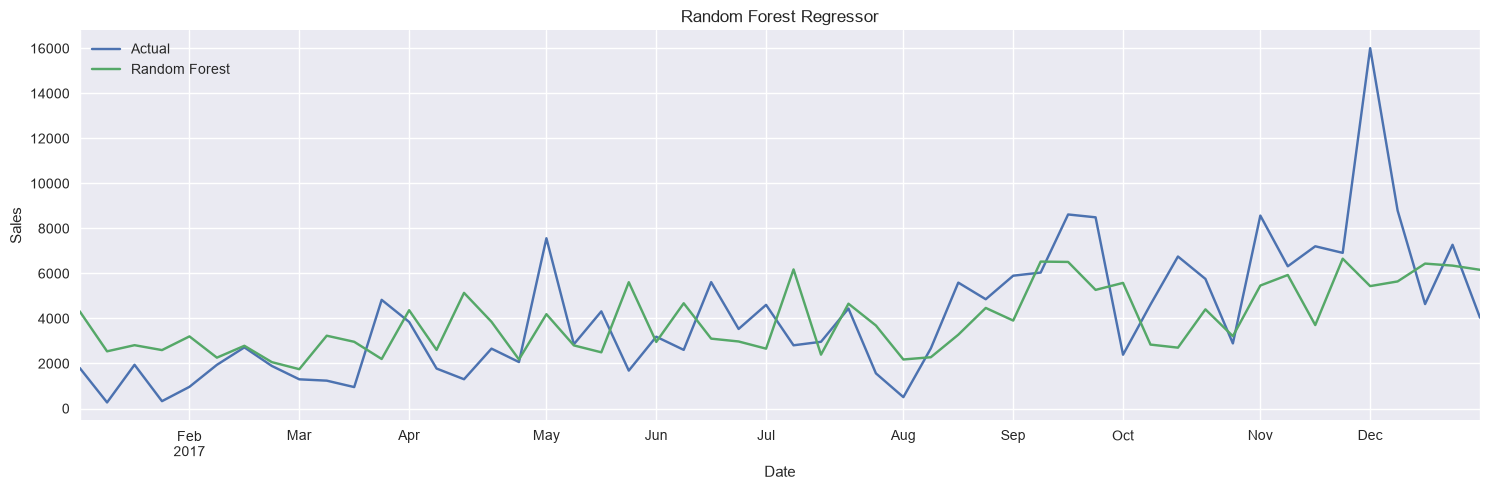

In [106]:
fig, ax = plt.subplots(figsize=(15, 5))

y_test.plot(ax=ax, label='Actual')
pd.Series(y_pred, index=y_test.index).plot(ax=ax, label='Random Forest')

ax.set_title('Random Forest Regressor')
ax.set_xlabel('Date')
ax.set_ylabel('Sales')
ax.legend()

plt.tight_layout()
plt.show()

In [108]:
from sklearn.ensemble import GradientBoostingRegressor

model_gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

model_gb.fit(X_train, y_train)

y_pred_gb = model_gb.predict(X_test)

In [109]:
print('MAE:', mean_absolute_error(y_test, y_pred_gb))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred_gb)))

MAE: 2319.237038506621
RMSE: 3023.0341127541697


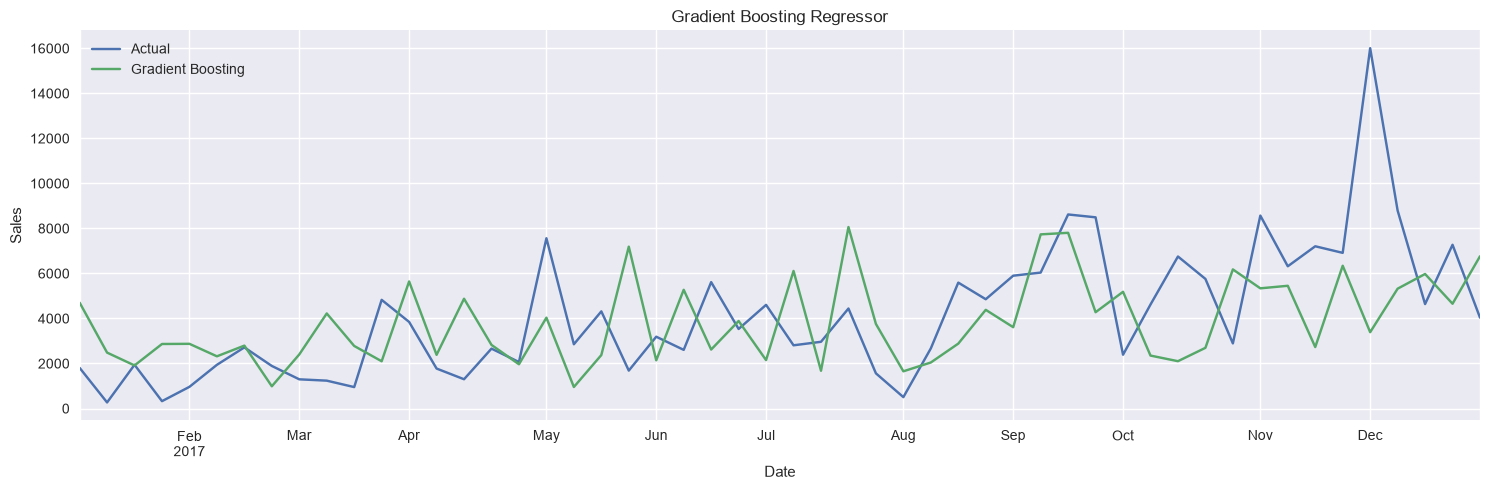

In [110]:
fig, ax = plt.subplots(figsize=(15, 5))

y_test.plot(ax=ax, label='Actual')
pd.Series(y_pred_gb, index=y_test.index).plot(ax=ax, label='Gradient Boosting')

ax.set_title('Gradient Boosting Regressor')
ax.set_xlabel('Date')
ax.set_ylabel('Sales')
ax.legend()

plt.tight_layout()
plt.show()

# 9. Создайте Streamlit-приложение, в которое пользователь сможет загрузить свой файл с временным рядом, и получить результат предсказания, а так же метрики и интерпретацию результатов

In [ ]:
# pip install streamlit prophet openpyxl matplotlib
# pip install plotly

10*. Если останется время, можно попробовать дополнительно одну из библиотек: 
* [Darts](https://habr.com/ru/articles/659405/)
* [Merlion](https://habr.com/ru/companies/sportmaster_lab/articles/792318/)
* [tsfresh](https://tsfresh.readthedocs.io/en/latest/)
* [Kats](https://github.com/facebookresearch/Kats)
* [autots](https://winedarksea.github.io/AutoTS/build/html/source/tutorial.html)

In [111]:
# pip install autots

from autots import AutoTS
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

In [116]:
train = data_week.iloc[:-52].to_frame()
test = data_week.iloc[-52:]

model_autots = AutoTS(
    forecast_length=52,
    frequency='infer',
    ensemble='simple',
    max_generations=5,
    num_validations=2,
    model_list='fast',
    n_jobs=1
)

model_autots = model_autots.fit(train)

Data frequency is: W-SUN, used frequency is: W-SUN
Too many training validations for length of data provided, decreasing num_validations to 1
Model Number: 1 with model AverageValueNaive in generation 0 of 5
Model Number: 2 with model AverageValueNaive in generation 0 of 5
Model Number: 3 with model AverageValueNaive in generation 0 of 5
Model Number: 4 with model DatepartRegression in generation 0 of 5
Model Number: 5 with model ETS in generation 0 of 5
Model Number: 6 with model GLM in generation 0 of 5
Model Number: 7 with model GLS in generation 0 of 5
Model Number: 8 with model LastValueNaive in generation 0 of 5
Model Number: 9 with model LastValueNaive in generation 0 of 5
Model Number: 10 with model LastValueNaive in generation 0 of 5
Model Number: 11 with model SeasonalNaive in generation 0 of 5
Model Number: 12 with model SeasonalNaive in generation 0 of 5
Model Number: 13 with model VAR in generation 0 of 5
Template Eval Error: ValueError('Only gave one variable to VAR') in 

In [118]:
# Получаем прогноз
prediction = model_autots.predict()
forecast_autots = prediction.forecast['Sales']

In [119]:
# Считаем метрики
mae_autots = mean_absolute_error(test, forecast_autots)
rmse_autots = np.sqrt(mean_squared_error(test, forecast_autots))

print('MAE:', mae_autots)
print('RMSE:', rmse_autots)
print('Лучшая модель:', model_autots)

MAE: 1700.9815641458508
RMSE: 2282.1600624577836
Лучшая модель: Initiated AutoTS object with best model: 
Ensemble
{'fillna': 'cubic', 'transformations': {'0': 'ScipyFilter', '1': 'DatepartRegression'}, 'transformation_params': {'0': {'method': 'butter', 'method_args': {'N': 1, 'btype': 'highpass', 'analog': False, 'output': 'sos', 'Wn': 0.024390243902439025}}, '1': {'regression_model': {'model': 'ElasticNet', 'model_params': {'l1_ratio': 0.5, 'fit_intercept': True, 'selection': 'cyclic', 'max_iter': 1000}}, 'datepart_method': ['weekdayofmonth', 'common_fourier'], 'polynomial_degree': None, 'transform_dict': None, 'holiday_countries_used': False, 'lags': None, 'forward_lags': None}}}
{'model_name': 'BestN', 'model_count': 5, 'model_metric': 'mixed_metric', 'models': {'af0a63b320e03cd053ea1465d5c92a11': {'Model': 'SeasonalityMotif', 'ModelParameters': '{"window": 10, "point_method": "midhinge", "distance_metric": "minkowski", "k": 10, "datepart_method": "common_fourier_rw", "independent

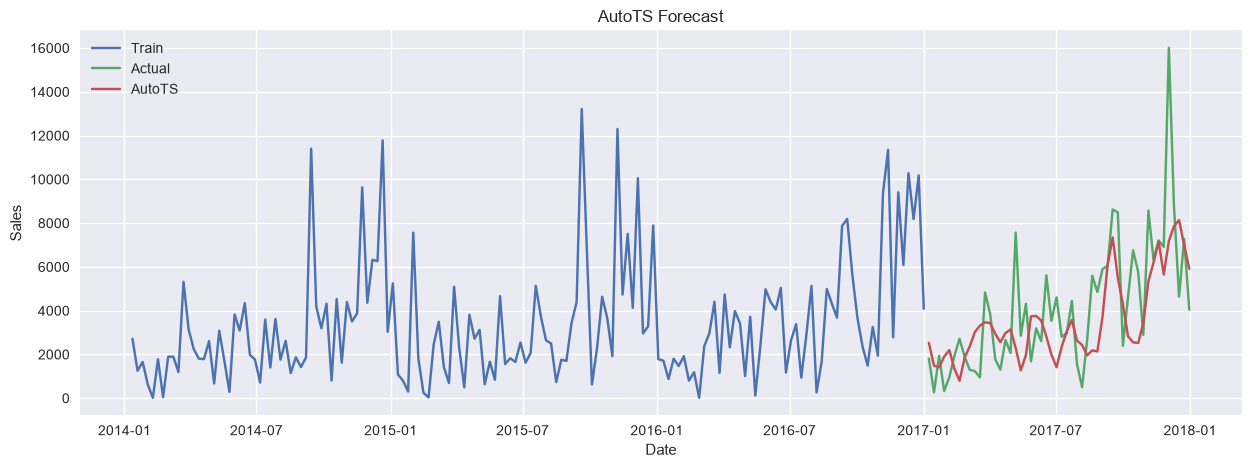

In [120]:
plt.figure(figsize=(15, 5))

plt.plot(train.index, train['Sales'], label='Train')
plt.plot(test.index, test, label='Actual')
plt.plot(forecast_autots.index, forecast_autots, label='AutoTS')

plt.title('AutoTS Forecast')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.show()

<img src="https://icons.iconarchive.com/icons/icons8/windows-8/256/Programming-Github-icon.png" width=32 /> Сохрани файл для __github__. 
